## Homework - 21 Matplotlib 

### Easy Questions

Q1. Load Dataset
Load sales_data.csv into a DataFrame and display the first 5 rows.

In [ ]:
import pandas as pd

sales_data = pd.read_csv("data/sales_data.csv")

sales_data.head()

,Date,Product_A,Product_B,Product_C
0,2023-01-01,151,128,58
1,2023-01-02,194,107,92
2,2023-01-03,191,146,79
3,2023-01-04,132,85,85
4,2023-01-05,115,89,93


Q2. Dataset Shape
Using customer_orders.csv, display total number of rows and columns.

In [ ]:
data = pd.read_csv("data/customer_orders.csv")

data.shape

(50, 5)

Q3. Total Sales Amount
Using Product_A, Product_B, and Product_C columns from sales_data.csv, calculate the total sales amount for each product.

In [ ]:
result = sales_data[["Product_A", "Product_B", "Product_C"]].sum()

result

Product_A    4548
Product_B    3444
Product_C    2429
dtype: int64

Q4. Average Student Grade
Using Math, English, and Science columns from student_grades.csv, calculate the average score for each subject.

In [ ]:
student_grades = pd.read_csv("data/student_grades.csv")

result = student_grades[["Math", "English", "Science"]].mean()

result

Math       81.60
English    81.78
Science    84.08
dtype: float64

Q5. Unique Departments
Using Department column from employee_information.csv, display all unique departments.

In [ ]:
employee = pd.read_csv("data/employee_information.csv")

result = employee["Department"].unique()

result

<StringArray>
['Finance', 'Sales', 'HR', 'IT', 'Marketing']
Length: 5, dtype: str

Q6. Payment Method Bar Chart
Using Product column from customer_orders.csv, create a bar chart showing the frequency of each product ordered.

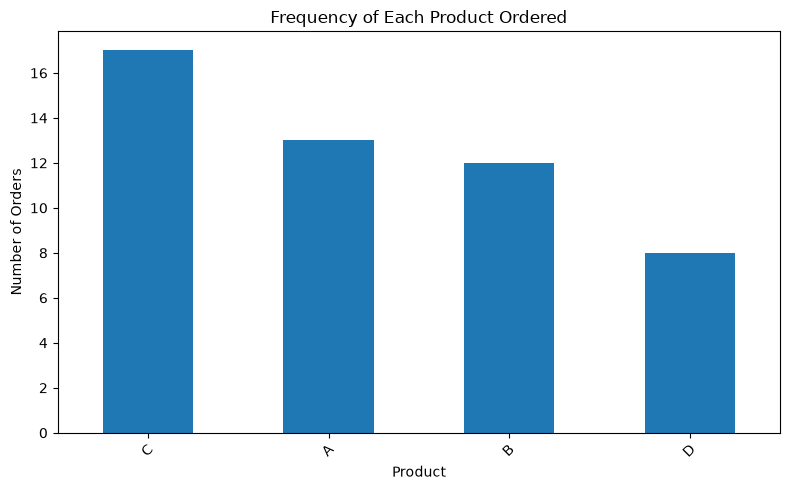

In [19]:
import matplotlib.pyplot as plt

# Har bir mahsulotning buyurtma sonini hisoblash
product_counts = data["Product"].value_counts()

# Bar chart
plt.figure(figsize=(8, 5))
product_counts.plot(kind="bar")

# Chart sozlamalari
plt.title("Frequency of Each Product Ordered")
plt.xlabel("Product")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.tight_layout()

# Chartni ko'rsatish
plt.show()

Q7. Quantity Filter
Using Quantity column from customer_orders.csv, filter rows where Quantity == 5.

In [20]:
data[data['Quantity'] == 5]

,Order_ID,Customer_ID,Product,Quantity,Total_Price
4,1005,243,B,5,482
14,1015,219,C,5,201
21,1022,210,D,5,372
27,1028,227,A,5,75
33,1034,235,C,5,323


Q8. Missing Values Check
Check all datasets for null (NaN) values using .isnull().sum().

In [21]:
print("Customer Orders")
print(data.isnull().sum())

print("\nSales Data")
print(sales_data.isnull().sum())

print("\nEmployees")
print(employee.isnull().sum())

print("\nProducts")
print(student_grades.isnull().sum())

Customer Orders
Order_ID       0
Customer_ID    0
Product        0
Quantity       0
Total_Price    0
dtype: int64

Sales Data
Date         0
Product_A    0
Product_B    0
Product_C    0
dtype: int64

Employees
Employee_ID           0
Name                  0
Department            0
Salary                0
Experience (Years)    0
dtype: int64

Products
Student_ID    0
Math          0
English       0
Science       0
dtype: int64


Q9. Rename Column
Using customer_orders.csv, rename the Total_Price column to Order_Total.

In [27]:
result = data.rename(columns={
    'Total_Price': 'Order_Total'
})

result

,Order_ID,Customer_ID,Product,Quantity,Order_Total
0,1001,233,A,6,210
1,1002,226,C,3,340
2,1003,208,D,8,296
3,1004,227,B,9,97
4,1005,243,B,5,482
5,1006,245,B,8,158
6,1007,214,C,6,181
7,1008,202,C,7,74
8,1009,217,A,7,264
9,1010,242,C,6,424


Q10. Gender Pie Chart
Using Department column from employee_information.csv, create a pie chart showing department distribution.

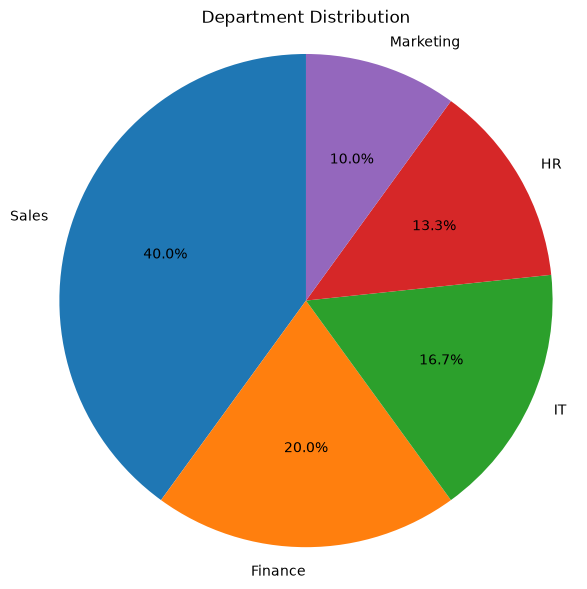

In [30]:
# Har bir bo'limdagi xodimlar sonini hisoblash
department_counts = employee["Department"].value_counts()

# Pie chart
plt.figure(figsize=(7, 7))
plt.pie(
    department_counts,
    labels=department_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

# Sarlavha
plt.title("Department Distribution")

# Diagrammani aylana ko'rinishida saqlash
plt.axis("equal")

plt.show()

### Medium Questions

Q11. Revenue by Category
Using Product_A, Product_B, and Product_C columns from sales_data.csv, calculate the total revenue for each product across all dates.

In [33]:
result = (
    sales_data[["Product_A", "Product_B", "Product_C"]]
    .sum()
    .reset_index()
)

result.columns = ["Product", "Total_Revenue"]

result

,Product,Total_Revenue
0,Product_A,4548
1,Product_B,3444
2,Product_C,2429


Q12. Daily Sales Trend
Using Date and Product_A columns from sales_data.csv, create a line chart showing the daily sales trend for Product_A.

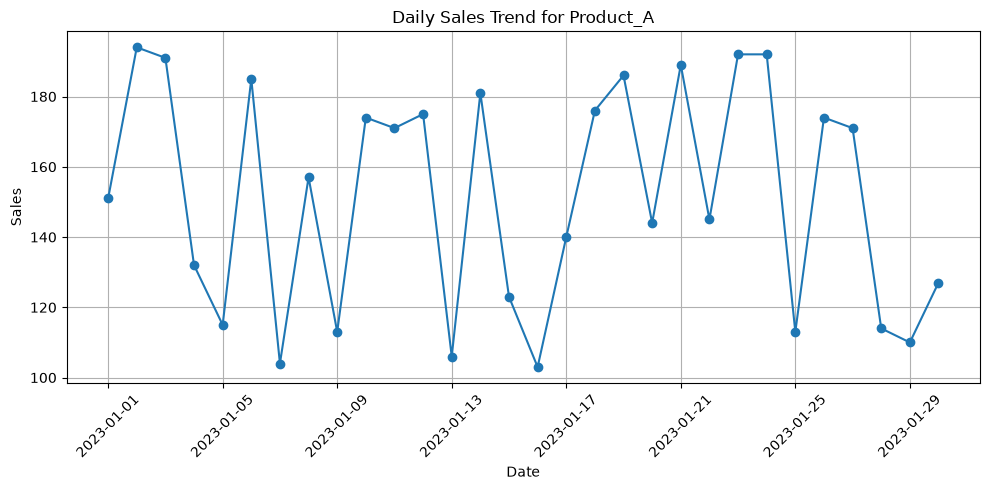

In [42]:
# Date ustunini datetime formatiga o'tkazish
sales_data["Date"] = pd.to_datetime(sales_data["Date"])

# Line chart
plt.figure(figsize=(10, 5))
plt.plot(sales_data["Date"], sales_data["Product_A"], marker="o")

# Chart sozlamalari
plt.title("Daily Sales Trend for Product_A")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

Q13. Average Salary by Gender
Using Department and Salary columns from employee_information.csv, calculate the average salary by department.

In [43]:
result = employee.groupby('Department', as_index=False).agg(
    AverageSalary=('Salary', 'mean')
)

result

,Department,AverageSalary
0,Finance,63473.833333
1,HR,77689.000000
2,IT,65290.000000
3,Marketing,68457.666667
4,Sales,69817.250000


Q14. Tax Calculation
Using Total_Price column from customer_orders.csv, create a Tax_Amount column equal to 10% of Total_Price.

In [44]:
data['Tax_Amount'] = data['Total_Price'] * 0.1

data

,Order_ID,Customer_ID,Product,Quantity,Total_Price,Tax_Amount
0,1001,233,A,6,210,21.0
1,1002,226,C,3,340,34.0
2,1003,208,D,8,296,29.6
3,1004,227,B,9,97,9.7
4,1005,243,B,5,482,48.2
5,1006,245,B,8,158,15.8
6,1007,214,C,6,181,18.1
7,1008,202,C,7,74,7.4
8,1009,217,A,7,264,26.4
9,1010,242,C,6,424,42.4


Q15. Shipping Cost Histogram
Using Total_Price column from customer_orders.csv, create a histogram to visualize the distribution of order prices.

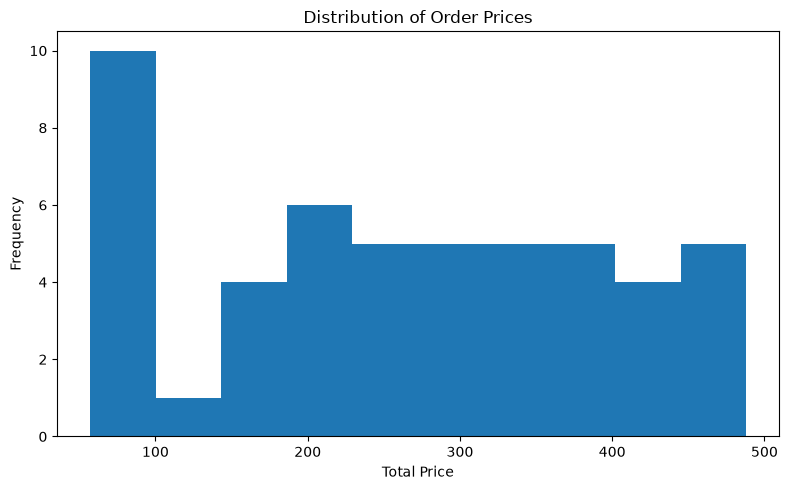

In [48]:
plt.figure(figsize=(8, 5))
plt.hist(data["Total_Price"], bins=10)

plt.title("Distribution of Order Prices")
plt.xlabel("Total Price")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

Q16. Top Expensive Products
Using Product and Total_Price columns from customer_orders.csv, display the top 5 highest-value orders.

In [54]:
result = data[['Product', 'Total_Price']].sort_values(by='Total_Price', ascending=False).head()

result

,Product,Total_Price
47,B,488
29,C,486
49,B,485
4,B,482
17,B,446


Q17. Electronics Without Returns
Using Product and Quantity columns from customer_orders.csv, filter orders where Product == "A" and Quantity > 3.

In [59]:
data[(data['Product'] == 'A') & (data['Quantity'] > 3)]

,Order_ID,Customer_ID,Product,Quantity,Total_Price,Tax_Amount
0,1001,233,A,6,210,21.0
8,1009,217,A,7,264,26.4
10,1011,238,A,7,352,35.2
18,1019,206,A,9,372,37.2
20,1021,206,A,6,65,6.5
25,1026,231,A,6,393,39.3
26,1027,234,A,8,402,40.2
27,1028,227,A,5,75,7.5
28,1029,249,A,6,78,7.8
45,1046,224,A,6,408,40.8


Q18. Category Box Plot
Using Product and Total_Price columns from customer_orders.csv, create a box plot for Total_Price by product type.

<Figure size 800x500 with 0 Axes>

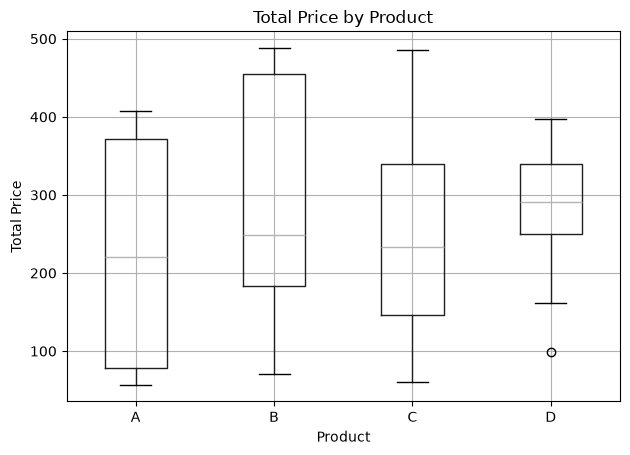

In [60]:
plt.figure(figsize=(8, 5))

data.boxplot(
    column="Total_Price",
    by="Product"
)

plt.title("Total Price by Product")
plt.suptitle("")      # Qo'shimcha avtomatik sarlavhani olib tashlaydi
plt.xlabel("Product")
plt.ylabel("Total Price")

plt.tight_layout()
plt.show()

Q19. Correlation Analysis
Using Total_Price and Quantity columns from customer_orders.csv, calculate the correlation between both columns.

In [61]:
result = data["Total_Price"].corr(data["Quantity"])

result

np.float64(-0.0861476928709186)

Q20. Scatter Plot Analysis
Using Salary and Experience (Years) columns from employee_information.csv, create a scatter plot with title and grid.

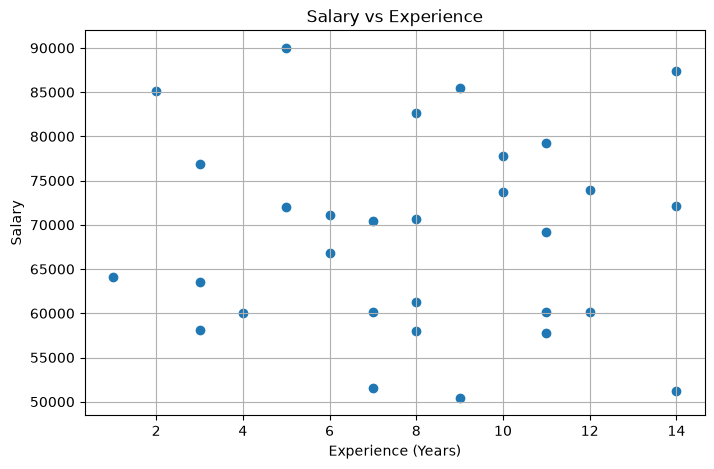

In [62]:
plt.figure(figsize=(8, 5))

plt.scatter(
    employee["Experience (Years)"],
    employee["Salary"]
)

plt.title("Salary vs Experience")
plt.xlabel("Experience (Years)")
plt.ylabel("Salary")
plt.grid(True)

plt.show()

### Hard Questions

Q21. Sales KPI Visualization Dashboard — Using sales_data.csv, create a subplot dashboard with: (1) a bar chart for total revenue per product (Product_A, Product_B, Product_C), (2) a line chart for monthly sales trends of all three products, (3) annotate the highest revenue date on the line chart, and (4) identify seasonal revenue patterns.

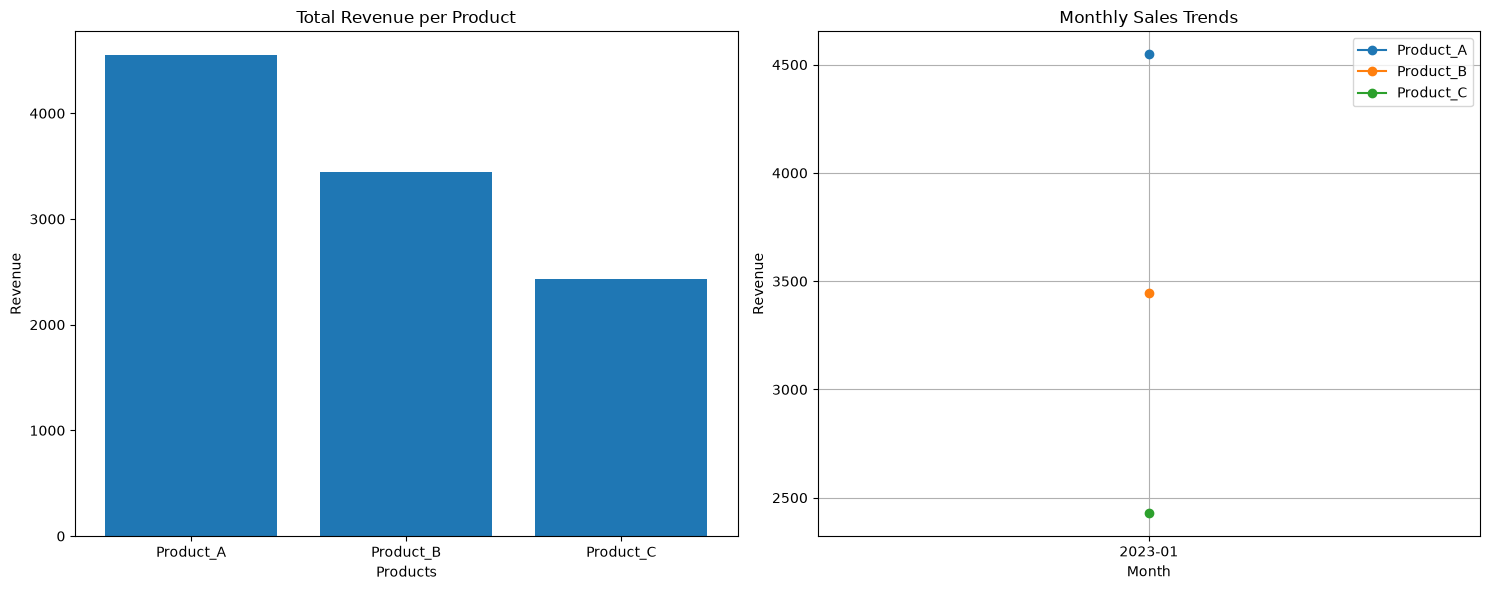

Highest Revenue Month: 2023-01
Highest Revenue: 10421

Monthly Revenue
Month
2023-01    10421
Freq: M, Name: Total, dtype: int64


In [69]:
# Date ustunini datetime formatiga o'tkazish
sales_data["Date"] = pd.to_datetime(sales_data["Date"])

# -----------------------------
# 1. Total Revenue per Product
# -----------------------------
total_revenue = sales_data[
    ["Product_A", "Product_B", "Product_C"]
].sum()

# -----------------------------
# 2. Monthly Sales Trends
# -----------------------------
sales_data["Month"] = sales_data["Date"].dt.to_period("M")

monthly_sales = sales_data.groupby("Month")[
    ["Product_A", "Product_B", "Product_C"]
].sum()

# Har oy uchun jami revenue
monthly_sales["Total"] = monthly_sales.sum(axis=1)

# Eng yuqori revenue bo'lgan oy
highest_month = monthly_sales["Total"].idxmax()
highest_value = monthly_sales.loc[highest_month, "Total"]

# -----------------------------
# Dashboard
# -----------------------------
fig, ax = plt.subplots(1, 2, figsize=(15, 6))

# -----------------------------
# Bar Chart
# -----------------------------
ax[0].bar(
    total_revenue.index,
    total_revenue.values
)

ax[0].set_title("Total Revenue per Product")
ax[0].set_xlabel("Products")
ax[0].set_ylabel("Revenue")

# -----------------------------
# Line Chart
# -----------------------------
for product in ["Product_A", "Product_B", "Product_C"]:
    ax[1].plot(
        monthly_sales.index.astype(str),
        monthly_sales[product],
        marker="o",
        label=product
    )

# Highest Revenue Annotation
ax[1].annotate(
    "Highest Revenue",
    xy=(str(highest_month), highest_value),
    xytext=(str(highest_month), highest_value + 100),
    arrowprops=dict(arrowstyle="->")
)

ax[1].set_title("Monthly Sales Trends")
ax[1].set_xlabel("Month")
ax[1].set_ylabel("Revenue")
ax[1].legend()
ax[1].grid(True)

plt.tight_layout()
plt.show()

# -----------------------------
# Seasonal Pattern
# -----------------------------
print("Highest Revenue Month:", highest_month)
print("Highest Revenue:", highest_value)

print("\nMonthly Revenue")
print(monthly_sales["Total"])

Q22. Customer Behavior Visualization Engine — Using customer_orders.csv, create a subplot dashboard with: (1) a histogram for Quantity distribution, (2) a scatter plot for Quantity vs Total_Price, (3) a box plot for Total_Price by Product, and (4) a bar chart for order count per Product. Detect quantity outliers using IQR method.

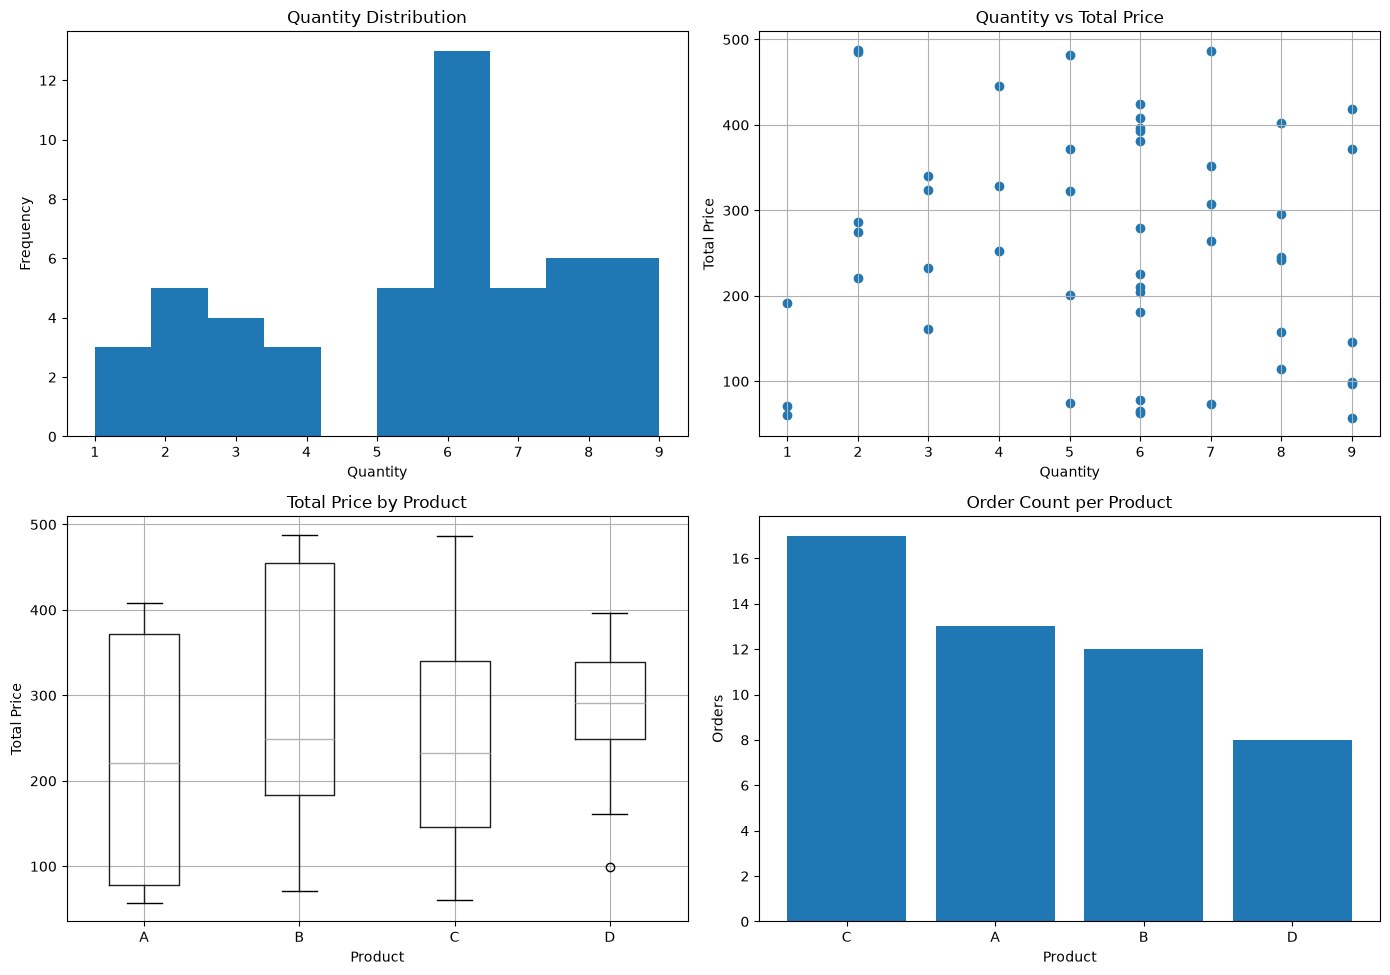

Quantity Outliers
Empty DataFrame
Columns: [Order_ID, Customer_ID, Product, Quantity, Total_Price, Tax_Amount]
Index: []


In [64]:
# Dashboard
fig, ax = plt.subplots(2, 2, figsize=(14, 10))

# 1. Histogram
ax[0, 0].hist(data["Quantity"], bins=10)
ax[0, 0].set_title("Quantity Distribution")
ax[0, 0].set_xlabel("Quantity")
ax[0, 0].set_ylabel("Frequency")

# 2. Scatter Plot
ax[0, 1].scatter(
    data["Quantity"],
    data["Total_Price"]
)
ax[0, 1].set_title("Quantity vs Total Price")
ax[0, 1].set_xlabel("Quantity")
ax[0, 1].set_ylabel("Total Price")
ax[0, 1].grid(True)

# 3. Box Plot
data.boxplot(
    column="Total_Price",
    by="Product",
    ax=ax[1, 0]
)
ax[1, 0].set_title("Total Price by Product")
ax[1, 0].set_xlabel("Product")
ax[1, 0].set_ylabel("Total Price")

# 4. Bar Chart
product_count = data["Product"].value_counts()

ax[1, 1].bar(
    product_count.index,
    product_count.values
)
ax[1, 1].set_title("Order Count per Product")
ax[1, 1].set_xlabel("Product")
ax[1, 1].set_ylabel("Orders")

plt.suptitle("")
plt.tight_layout()
plt.show()

# -------------------------
# IQR Outlier Detection
# -------------------------

Q1 = data["Quantity"].quantile(0.25)
Q3 = data["Quantity"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = data[
    (data["Quantity"] < lower) |
    (data["Quantity"] > upper)
]

print("Quantity Outliers")
print(outliers)

Q23. Employee Analytics Visualization System — Using employee_information.csv, create a subplot dashboard with: (1) a histogram for Salary distribution, (2) a bar chart for average Salary by Department, (3) a scatter plot for Experience (Years) vs Salary, and (4) a box plot for Salary by Department. Identify departments with salary anomalies using IQR.

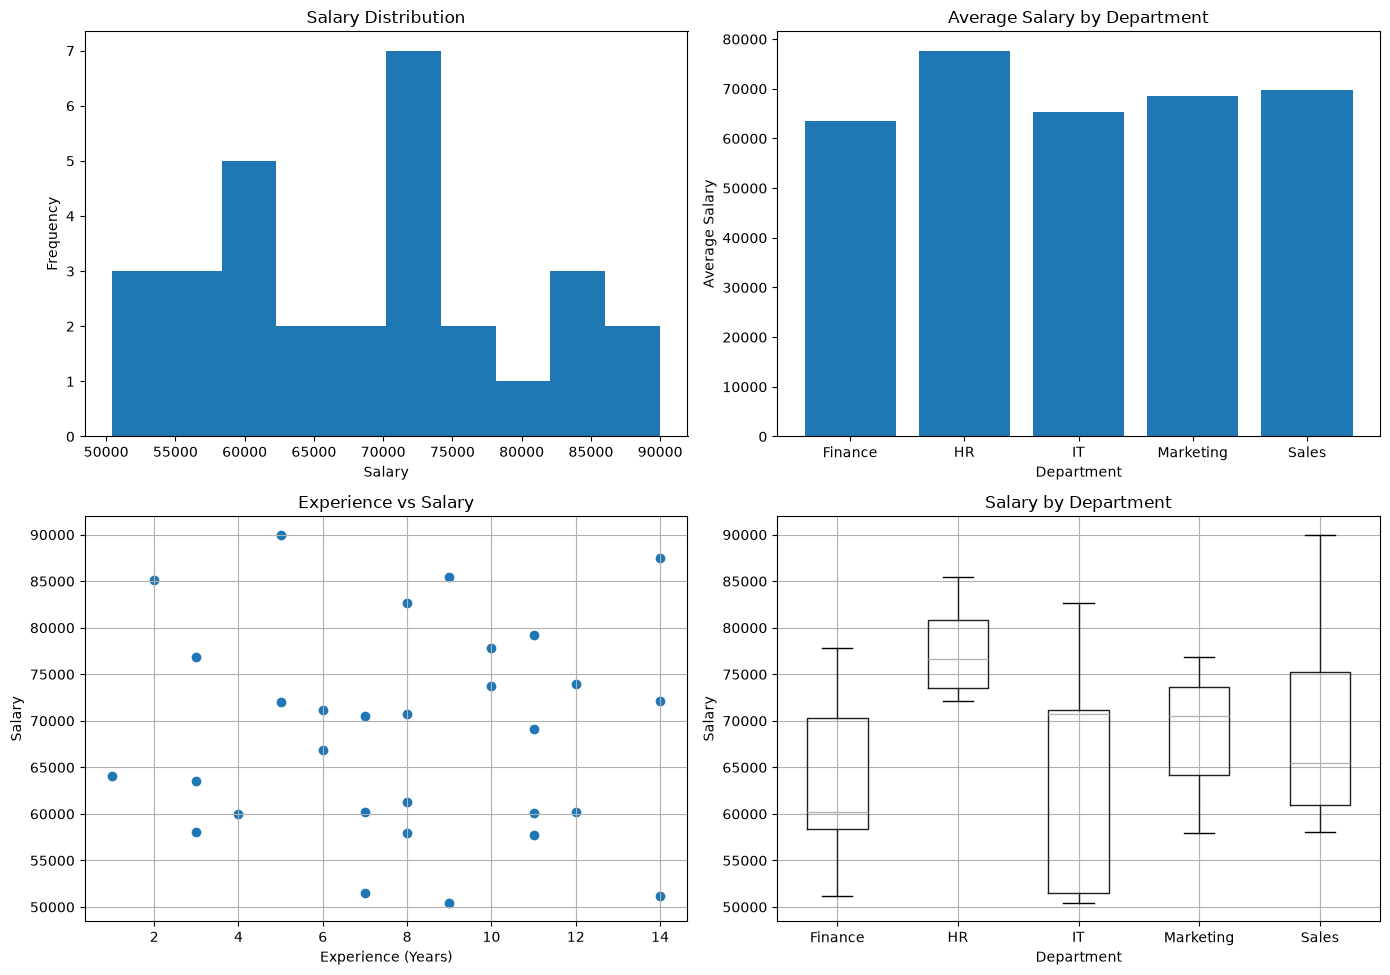

Salary Outliers
Empty DataFrame
Columns: [Employee_ID, Name, Department, Salary, Experience (Years)]
Index: []

Departments with Salary Anomalies:
<StringArray>
[]
Length: 0, dtype: str


In [66]:
# Dashboard
fig, ax = plt.subplots(2, 2, figsize=(14, 10))

# 1. Salary Histogram
ax[0, 0].hist(employee["Salary"], bins=10)
ax[0, 0].set_title("Salary Distribution")
ax[0, 0].set_xlabel("Salary")
ax[0, 0].set_ylabel("Frequency")

# 2. Average Salary by Department
avg_salary = employee.groupby("Department")["Salary"].mean()

ax[0, 1].bar(avg_salary.index, avg_salary.values)
ax[0, 1].set_title("Average Salary by Department")
ax[0, 1].set_xlabel("Department")
ax[0, 1].set_ylabel("Average Salary")

# 3. Scatter Plot
ax[1, 0].scatter(
    employee["Experience (Years)"],
    employee["Salary"]
)
ax[1, 0].set_title("Experience vs Salary")
ax[1, 0].set_xlabel("Experience (Years)")
ax[1, 0].set_ylabel("Salary")
ax[1, 0].grid(True)

# 4. Box Plot
employee.boxplot(
    column="Salary",
    by="Department",
    ax=ax[1, 1]
)

ax[1, 1].set_title("Salary by Department")
ax[1, 1].set_xlabel("Department")
ax[1, 1].set_ylabel("Salary")

plt.suptitle("")
plt.tight_layout()
plt.show()

# -----------------------------
# Salary Outliers using IQR
# -----------------------------

Q1 = employee["Salary"].quantile(0.25)
Q3 = employee["Salary"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

salary_outliers = employee[
    (employee["Salary"] < lower) |
    (employee["Salary"] > upper)
]

print("Salary Outliers")
print(salary_outliers)

# Departments with salary anomalies
print("\nDepartments with Salary Anomalies:")
print(salary_outliers["Department"].unique())

### 2 Easy Questions From Next Topic – Practice Lesson

Q24. Combined Analysis
Using sales_data.csv, calculate the average daily sales for Product_A, Product_B, and Product_C, then visualize results with a bar chart.

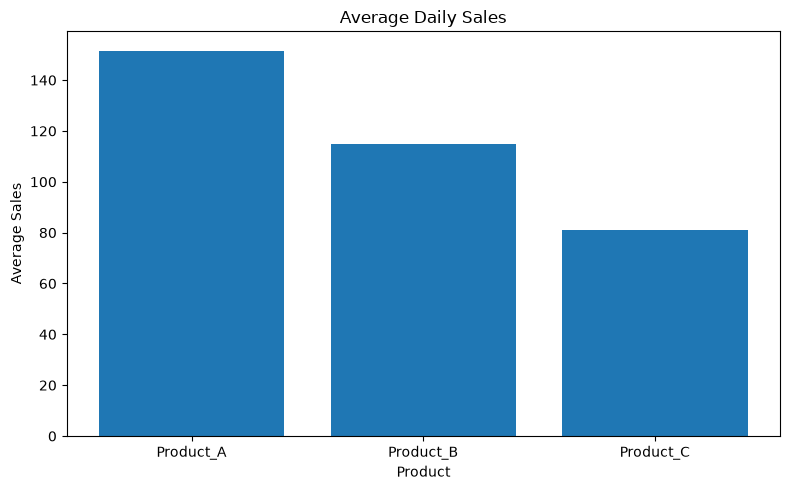

In [67]:
# Har bir mahsulotning o'rtacha kunlik sotuvi
average_sales = sales_data[
    ["Product_A", "Product_B", "Product_C"]
].mean()

# Bar Chart
plt.figure(figsize=(8, 5))

plt.bar(
    average_sales.index,
    average_sales.values
)

plt.title("Average Daily Sales")
plt.xlabel("Product")
plt.ylabel("Average Sales")

plt.tight_layout()
plt.show()

Q25. Student Grade Visualization
Using student_grades.csv, calculate the average score for Math, English, and Science columns, then create a bar chart comparing subject averages.

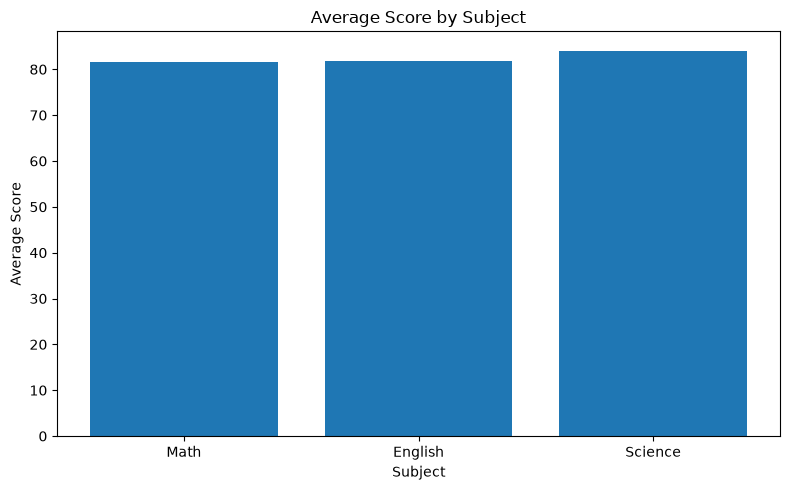

In [68]:
# Fanlar bo'yicha o'rtacha baholar
average_scores = student_grades[
    ["Math", "English", "Science"]
].mean()

# Bar Chart
plt.figure(figsize=(8, 5))

plt.bar(
    average_scores.index,
    average_scores.values
)

plt.title("Average Score by Subject")
plt.xlabel("Subject")
plt.ylabel("Average Score")

plt.tight_layout()
plt.show()